# 선택 과제 A — YOLO 서비스 (탐지 + 분할)

사진을 넣으면 **박스(탐지, `yolo26n.pt`)** 와 **마스크(분할, `yolo26n-seg.pt`)** 를 보여 주고, 임계값 **0.25 / 0.50** 결과를 비교합니다.

- 설정: `imgsz=640`, `device=cpu`, `conf=0.25, 0.50` (+ 참고용 0.10)
- 저장 위치: `outputs/yolo/<사진이름>/` — 결과 이미지, 좌표 JSON, 마스크 PNG, `summary.json`
- 실행 기록: `manifest.json`

**다른 사진으로 바꾸려면** `input/` 폴더에 사진을 넣고 아래 셀을 다시 실행하세요.

In [1]:
# 1) 설치 (처음 한 번)
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
# 2) 실행: input/ 의 모든 사진 → outputs/yolo/ 에 저장
!python yolo_service.py > run_log.txt && echo 완료 && cat manifest.json

완료
{
  "created_at": "2026-11-10T07:01:24+00:00",
  "inputs": [
    {
      "file": "input/bus.jpg"
    }
  ],
  "models": {
    "detect": "yolo26n.pt",
    "segment": "yolo26n-seg.pt"
  },
  "settings": {
    "imgsz": 640,
    "device": "cpu",
    "conf": [
      0.1,
      0.25,
      0.5
    ]
  },
  "versions": {
    "python": "3.13.18",
    "ultralytics": "8.4.208",
    "torch": "2.15.0+cu132",
    "opencv": "5.0.0"
  },
  "run_location": {
    "where": "Claude(Cowork) 클라우드 샌드박스 — 리눅스 컨테이너, GPU 없음(CPU)",
    "os": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
    "machine": "x86_64"
  },
  "outputs": "outputs/yolo/<사진이름>/ (결과 이미지 .jpg, 좌표 .json, 마스크 폴더, summary.json)"
}

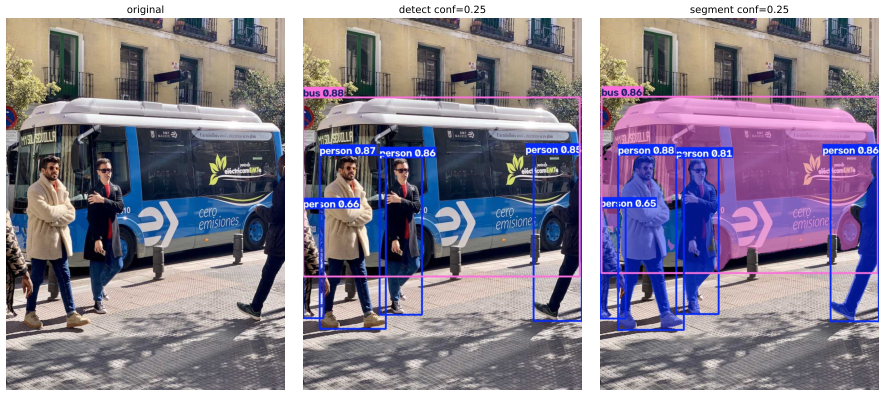

In [3]:
# 3) 원본 · 박스 · 마스크 나란히 보기
import json, matplotlib.pyplot as plt, matplotlib.image as mpimg
from pathlib import Path
plt.rcParams["font.family"] = "DejaVu Sans"; plt.rcParams["figure.dpi"] = 60
for img in sorted(Path("input").glob("*.[jp][pn]g")):
    d = Path("outputs/yolo") / img.stem
    fig, ax = plt.subplots(1, 3, figsize=(15, 6.5))
    for a, (p, t) in zip(ax, [(img, "original"), (d/"detect_conf0.25.jpg", "detect conf=0.25"), (d/"segment_conf0.25.jpg", "segment conf=0.25")]):
        a.imshow(mpimg.imread(p)); a.set_title(t); a.axis("off")
    plt.tight_layout(); plt.show()

In [4]:
# 4) 임계값 비교: 0.25 vs 0.50, 그리고 0.25 아래 후보(참고 0.10)
for img in sorted(Path("input").glob("*.[jp][pn]g")):
    d = Path("outputs/yolo") / img.stem
    for task in ["detect", "segment"]:
        for conf in ["0.10", "0.25", "0.50"]:
            j = json.loads((d / f"{task}_conf{conf}.json").read_text())
            items = ", ".join(f"{x['class_name']}({x['confidence']:.2f})" for x in j["detections"])
            print(f"{img.name:10s} {task:8s} conf={conf}: {j['count']}개 → {items}")
        print()

bus.jpg    detect   conf=0.10: 6개 → bus(0.88), person(0.87), person(0.86), person(0.85), person(0.66), stop sign(0.13)
bus.jpg    detect   conf=0.25: 5개 → bus(0.88), person(0.87), person(0.86), person(0.85), person(0.66)
bus.jpg    detect   conf=0.50: 5개 → bus(0.88), person(0.87), person(0.86), person(0.85), person(0.66)

bus.jpg    segment  conf=0.10: 5개 → person(0.88), person(0.86), bus(0.86), person(0.81), person(0.65)
bus.jpg    segment  conf=0.25: 5개 → person(0.88), person(0.86), bus(0.86), person(0.81), person(0.65)
bus.jpg    segment  conf=0.50: 5개 → person(0.88), person(0.86), bus(0.86), person(0.81), person(0.65)



{
  "class_id": 5,
  "class_name": "bus",
  "confidence": 0.8806,
  "xyxy_px": [
    0.0,
    230.5,
    803.2,
    750.7
  ],
  "xyxy_norm": [
    0.0,
    0.2134,
    0.9916,
    0.6951
  ],
  "id": 0
}


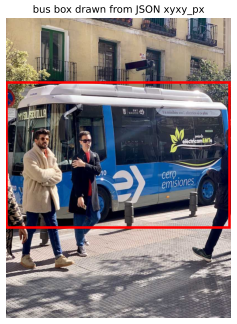

In [5]:
# 5) 박스 하나를 골라 JSON 좌표와 연결해 보기 (bus.jpg 의 bus)
j = json.loads(Path("outputs/yolo/bus/detect_conf0.25.json").read_text())
bus = [x for x in j["detections"] if x["class_name"] == "bus"][0]
print(json.dumps(bus, indent=2))
im = mpimg.imread("input/bus.jpg"); x1, y1, x2, y2 = bus["xyxy_px"]
fig, ax = plt.subplots(figsize=(5, 6.5)); ax.imshow(im); ax.axis("off")
ax.add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, ec="red", lw=3)); ax.set_title("bus box drawn from JSON xyxy_px"); plt.show()

In [6]:
# 6) 마스크 면적 vs 박스 면적 (박스 안에 배경이 얼마나 섞였나)
j = json.loads(Path("outputs/yolo/bus/segment_conf0.25.json").read_text())
for x in j["detections"]:
    print(f"{x['class_name']:7s} conf={x['confidence']:.2f}  마스크 {x['mask_area_px']:>7,}px / 박스 {x['box_area_px']:>7,}px = {x['mask_to_box_ratio']:.0%}")

person  conf=0.88  마스크  49,046px / 박스  97,053px = 50%
person  conf=0.86  마스크  21,190px / 박스  68,112px = 31%
bus     conf=0.86  마스크 255,100px / 박스 410,281px = 62%
person  conf=0.81  마스크  33,160px / 박스  56,023px = 59%
person  conf=0.65  마스크  10,681px / 박스  23,684px = 45%
